# PCA and t-SNE check if the population has sub-population

In [221]:
import pandas as pd
import numpy as np
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

In [2]:
import pandas as pd

In [4]:
# read the popLabel
pop_filtered_New = pd.read_csv("../../data01/filtered.popLabel",sep="\t")

colors = [
    '#d62728',  # Red
    '#ff7f0e',  # Orange
    '#2ca02c',  # Green
    '#9467bd',  # Purple
    '#8c564b',  # Brown
    '#1f77b4',  # Blue
    '#ffbb78',  # Light Orange
    '#98df8a',  # Light Green
    'black',    # Black
    '#c5b0d5',  # Light Purple
    '#7f7f7f',  # Gray
    '#ff1493',  # Deep Pink
    '#bcbd22',  # Olive
    '#aec7e8',  # Light Blue
    '#c49c94',  # Light Brown
    '#17becf',  # Cyan
        '#e377c2',  # Pink
]
markers=['o', 'v', '^', '<', '>', 's', 'p', '*', 'h', 'H', 'D', 'd']

unique_population = pop_filtered_New["population"].unique()
breed_info = pop_filtered_New
for i, population in enumerate(unique_population):
    unique_group = breed_info.loc[breed_info["population"]==population,"group"].unique()
    if i < len(colors):
        breed_info.loc[breed_info["population"]==population,"facecolor"]="white"
        breed_info.loc[breed_info["population"]==population,"edgecolor"]=colors[i]
    else:
        breed_info.loc[breed_info["population"]==population,"facecolor"]=colors[i % len(colors)]
        breed_info.loc[breed_info["population"]==population,"edgecolor"]=colors[i % len(colors)]
    for j,group in enumerate(unique_group):
        breed_info.loc[(breed_info["population"]==population) & (breed_info["group"]==group),"marker"]=markers[j]

breed_info_a  = breed_info


/var/folders/sq/vc6_dvd116b6pt9nrzq_m1100000gr/T/ipykernel_14464/1150404634.py:30: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'white' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  breed_info.loc[breed_info["population"]==population,"facecolor"]="white"
/var/folders/sq/vc6_dvd116b6pt9nrzq_m1100000gr/T/ipykernel_14464/1150404634.py:31: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '#d62728' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  breed_info.loc[breed_info["population"]==population,"edgecolor"]=colors[i]
/var/folders/sq/vc6_dvd116b6pt9nrzq_m1100000gr/T/ipykernel_14464/1150404634.py:36: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value 'o' has dtype incompatible with float64, please expl

In [5]:
breed_info.loc[breed_info['population']=="Duroc",'sample_id'].to_csv("../data02/Duroc.txt", index=False, header=False)
breed_info.loc[breed_info["population"]=="Yorkshire",'sample_id'].to_csv("../data02/Yorkshire.txt", index=False, header=False)
breed_info.loc[breed_info["population"]=="Landrace",'sample_id'].to_csv("../data02/Landrace.txt", index=False, header=False)
breed_info.loc[(breed_info["population"]!="AnqingSixendwhite") & (breed_info["population"]!="WannanBlack"),'sample_id'].to_csv("../data02/total.txt", index=False, header=False)

In [6]:
df_pca=pd.read_table("../data02/merged_total.eigenvec",sep=" ",header=None)
df_pca = df_pca.merge(breed_info,left_on=1,right_on="sample_id",how="inner")
f=open("../data02/merged_total.eigenval")
value=[]
line=f.readline()
while line!="":
    value.append(float(line.strip("\n")))
    line=f.readline()
f.close()

In [7]:
df_pca_D =pd.read_table("../data02/merged_Duroc.eigenvec",sep=" ",header=None)
df_pca_D = df_pca_D.merge(breed_info_a,left_on=1,right_on="sample_id",how="inner")
f=open("../data02/merged_Duroc.eigenval")
value_D=[]
line=f.readline()
while line!="":
    value_D.append(float(line.strip("\n")))
    line=f.readline()
f.close()

In [8]:
df_pca_Y =pd.read_table("../data02/merged_Yorkshire.eigenvec",sep=" ",header=None)
df_pca_Y = df_pca_Y.merge(breed_info_a,left_on=1,right_on="sample_id",how="inner")
f=open("../data02/merged_Yorkshire.eigenval")
value_Y=[]
line=f.readline()
while line!="":
    value_Y.append(float(line.strip("\n")))
    line=f.readline()
f.close()

In [9]:
df_pca_L =pd.read_table("../data02/merged_Landrace.eigenvec",sep=" ",header=None)
df_pca_L = df_pca_L.merge(breed_info_a,left_on=1,right_on="sample_id",how="inner")
f=open("../data02/merged_Landrace.eigenval")
value_L=[]
line=f.readline()
while line!="":
    value_L.append(float(line.strip("\n")))
    line=f.readline()
f.close()

In [118]:
camera_x = 0.5
camera_y = -1.179
camera_z = 2.134

# 转换为Matplotlib的elev和azim（近似公式）
# 计算方位角 (azimuth)
azim = np.degrees(np.arctan2(camera_y, camera_x))

# 计算仰角 (elevation)
r_xy = np.sqrt(camera_x**2 + camera_y**2)
elev = np.degrees(np.arctan2(camera_z, r_xy))
elev,azim

(59.0314887615206, -67.01877170022013)

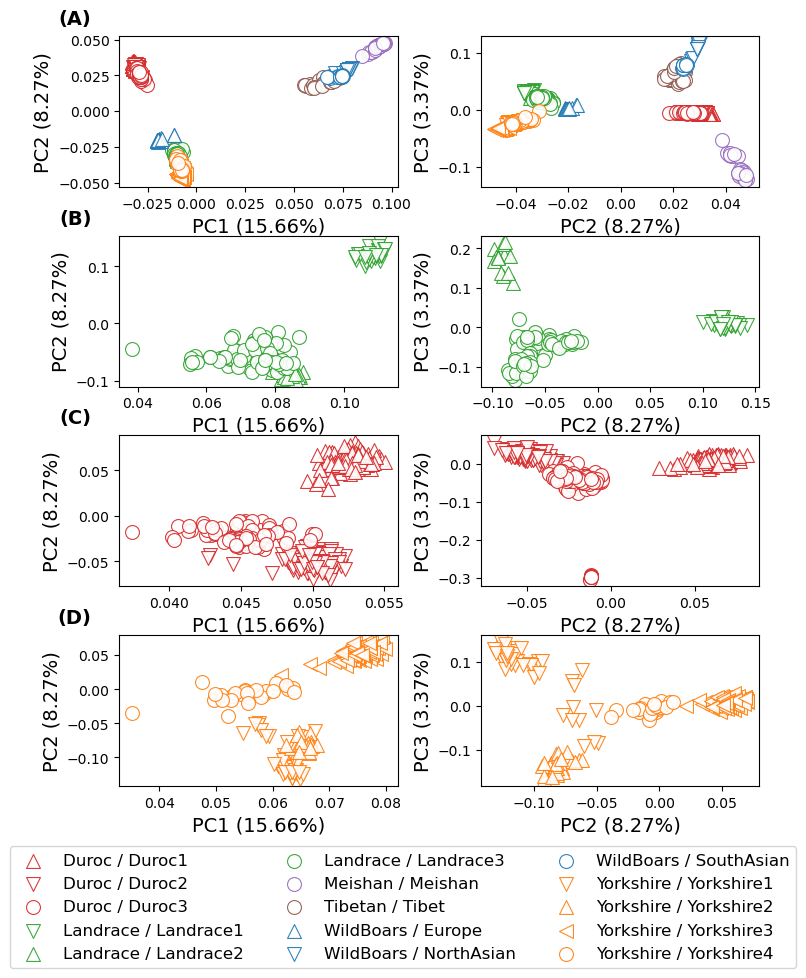

In [218]:
left_margin   = 0.15
right_margin  = 0.95
top_margin    = 0.95
bottom_margin = 0.0
# gs = GridSpec(3, 2, height_ratios=[2, 2, 1])  # 2 rows, 2 columns, row heights ratio
# 2. Initialize Figure
fig = plt.figure(figsize=(8, 10)) # Height=15 to accommodate 5 rows

# 3. Create GridSpec with the fixed syntax
gs = GridSpec(nrows=5, ncols=2, 
            figure=fig,
            wspace=0.3,          # Width space between columns
            hspace=0.32,          # Height space between rows
            left=left_margin, 
            right=right_margin, 
            top=top_margin, 
            bottom=bottom_margin,)
plt.rcParams['font.family'] = ''
# Add subplots to the gridspec layout
ax1 = fig.add_subplot(gs[0, 0])  # First row, first column
ax2 = fig.add_subplot(gs[0, 1])  # First row, second column

for i in df_pca.groupby(["population","group"]):
    tem=i[1]
    PC1=tem[2]
    PC2=tem[3]
    sns.scatterplot(x=PC1, y=PC2, marker=tem["marker"].unique()[0], label=i[0][0]+" / "+i[0][1],ax=ax1,alpha=0.9,s=100,facecolors=tem["facecolor"].unique()[0], edgecolors=tem["edgecolor"].unique()[0],legend=False)
    
ax1.set_xlabel('PC1 ({:.2f}%)'.format(value[0]/sum(value)*100), fontsize=14)
ax1.set_ylabel('PC2 ({:.2f}%)'.format(value[1]/sum(value)*100), fontsize=14)
ax1.text(-0.1, 1.05, "(A)", transform=ax1.transAxes, 
         fontsize=14, fontweight='bold', va='bottom', ha='right')
for i in df_pca.groupby(["population","group"]):
    tem=i[1]
    PC2=tem[3]
    PC3=tem[4]
    sns.scatterplot(x=PC2, y=PC3, marker=tem["marker"].unique()[0], label=i[0][0]+" / "+i[0][1],ax=ax2,alpha=0.9,s=100,facecolors=tem["facecolor"].unique()[0], edgecolors=tem["edgecolor"].unique()[0],legend=False)
    
ax2.set_xlabel('PC2 ({:.2f}%)'.format(value[1]/sum(value)*100), fontsize=14)
ax2.set_ylabel('PC3 ({:.2f}%)'.format(value[2]/sum(value)*100), fontsize=14)

ax3 = fig.add_subplot(gs[1, 0])  # First row, first column
ax4 = fig.add_subplot(gs[1, 1])  # First row, second column

for i in df_pca_L.groupby(["population","group"]):
    tem=i[1]
    PC1=tem[2]
    PC2=tem[3]
    sns.scatterplot(x=PC1, y=PC2, marker=tem["marker"].unique()[0], label=i[0][0]+" / "+i[0][1],ax=ax3,alpha=0.9,s=100,facecolors=tem["facecolor"].unique()[0], edgecolors=tem["edgecolor"].unique()[0],legend=False)
    
ax3.set_xlabel('PC1 ({:.2f}%)'.format(value[0]/sum(value)*100), fontsize=14)
ax3.set_ylabel('PC2 ({:.2f}%)'.format(value[1]/sum(value)*100), fontsize=14)
ax3.text(-0.1, 1.05, "(B)", transform=ax3.transAxes, 
         fontsize=14, fontweight='bold', va='bottom', ha='right')
for i in df_pca_L.groupby(["population","group"]):
    tem=i[1]
    PC2=tem[3]
    PC3=tem[4]
    sns.scatterplot(x=PC2, y=PC3, marker=tem["marker"].unique()[0], label=i[0][0]+" / "+i[0][1],ax=ax4,alpha=0.9,s=100,facecolors=tem["facecolor"].unique()[0], edgecolors=tem["edgecolor"].unique()[0],legend=False)
    
ax4.set_xlabel('PC2 ({:.2f}%)'.format(value[1]/sum(value)*100), fontsize=14)
ax4.set_ylabel('PC3 ({:.2f}%)'.format(value[2]/sum(value)*100), fontsize=14)


ax5 = fig.add_subplot(gs[2, 0])  # First row, first column
ax6 = fig.add_subplot(gs[2, 1])  # First row, second column

for i in df_pca_D.groupby(["population","group"]):
    tem=i[1]
    PC1=tem[2]
    PC2=tem[3]
    sns.scatterplot(x=PC1, y=PC2, marker=tem["marker"].unique()[0], label=i[0][0]+" / "+i[0][1],ax=ax5,alpha=0.9,s=100,facecolors=tem["facecolor"].unique()[0], edgecolors=tem["edgecolor"].unique()[0],legend=False)
    
ax5.set_xlabel('PC1 ({:.2f}%)'.format(value[0]/sum(value)*100), fontsize=14)
ax5.set_ylabel('PC2 ({:.2f}%)'.format(value[1]/sum(value)*100), fontsize=14)
ax5.text(-0.1, 1.05, "(C)", transform=ax5.transAxes, 
         fontsize=14, fontweight='bold', va='bottom', ha='right')
for i in df_pca_D.groupby(["population","group"]):
    tem=i[1]
    PC2=tem[3]
    PC3=tem[4]
    sns.scatterplot(x=PC2, y=PC3, marker=tem["marker"].unique()[0], label=i[0][0]+" / "+i[0][1],ax=ax6,alpha=0.9,s=100,facecolors=tem["facecolor"].unique()[0], edgecolors=tem["edgecolor"].unique()[0],legend=False)
    
ax6.set_xlabel('PC2 ({:.2f}%)'.format(value[1]/sum(value)*100), fontsize=14)
ax6.set_ylabel('PC3 ({:.2f}%)'.format(value[2]/sum(value)*100), fontsize=14)

ax7 = fig.add_subplot(gs[3, 0])  # First row, first column
ax8 = fig.add_subplot(gs[3, 1])  # First row, second column

for i in df_pca_Y.groupby(["population","group"]):
    tem=i[1]
    PC1=tem[2]
    PC2=tem[3]
    sns.scatterplot(x=PC1, y=PC2, marker=tem["marker"].unique()[0], label=i[0][0]+" / "+i[0][1],ax=ax7,alpha=0.9,s=100,facecolors=tem["facecolor"].unique()[0], edgecolors=tem["edgecolor"].unique()[0],legend=False)
    
ax7.set_xlabel('PC1 ({:.2f}%)'.format(value[0]/sum(value)*100), fontsize=14)
ax7.set_ylabel('PC2 ({:.2f}%)'.format(value[1]/sum(value)*100), fontsize=14)
ax7.text(-0.1, 1.05, "(D)", transform=ax7.transAxes, 
         fontsize=14, fontweight='bold', va='bottom', ha='right')
for i in df_pca_Y.groupby(["population","group"]):
    tem=i[1]
    PC2=tem[3]
    PC3=tem[4]
    sns.scatterplot(x=PC2, y=PC3, marker=tem["marker"].unique()[0], label=i[0][0]+" / "+i[0][1],ax=ax8,alpha=0.9,s=100,facecolors=tem["facecolor"].unique()[0], edgecolors=tem["edgecolor"].unique()[0],legend=False)
    
ax8.set_xlabel('PC2 ({:.2f}%)'.format(value[1]/sum(value)*100), fontsize=14)
ax8.set_ylabel('PC3 ({:.2f}%)'.format(value[2]/sum(value)*100), fontsize=14)


handles, labels = ax1.get_legend_handles_labels()
ax7.legend(handles, labels, loc='center', bbox_to_anchor=(1.02, -0.8), ncol=3, fontsize=12)


fig.savefig("../data02/PCA_Total_D_Y_L3.png",dpi=300)